In [364]:
# Загрузка, обработка таблиц и подготовка выборок данных
import pandas as pd

# Визуализация данных, построение графиков распределений и боксплотов
import seaborn as sns

# Модуль базовых статистических тестов библиотеки SciPy
from scipy import stats

# Построение линейной модели для ANOVA (дисперсионного анализа)
from statsmodels.formula.api import ols

# Расчет таблицы дисперсионного анализа (ANOVA) по построенной модели
from statsmodels.stats.anova import anova_lm

# Инструменты statsmodels (для построения графиков квантилей QQ-plot)
import statsmodels.api as sm

# Проведение критерия Тьюки (Post-hoc анализ для попарных сравнений)
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# Функции для корреляционного анализа (коэффициенты Пирсона, Спирмена, Кендалла)
from scipy.stats import pearsonr, spearmanr, kendalltau



In [365]:
# Импортируем matplotlib для настройки параметров осей
import matplotlib.pyplot as plt

# Настраиваем минималистичный стиль и крупный читаемый шрифт
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.1)

# Задаем свою стильную палитру (Глубокий синий, Серый, Коралловый акцент)
my_palette = ["#1a365d", "#718096", "#e53e3e"]
sns.set_palette(my_palette)

# Убираем рамки графика сверху и справа для чистоты отображения
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

1. **Факторы зарплат:** Что сильнее всего влияет на зарплатную вилку вакансий в сфере Data Science?
2. **Распределение грейдов:** Как распределены позиции (грейды) сотрудников в компаниях разного размера? Какие выводы можно сделать на основе этого распределения?
3. **Выбор компании:** В компанию какого размера выгоднее устраиваться кандидатам уровней *Middle* и *Senior*?

In [366]:
data = pd.read_csv("datas/ds_salaries.csv", index_col=0)
data.head()

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,company_location,company_size
0,2020,MI,FT,Data Scientist,70000,EUR,79833,DE,DE,L
1,2020,SE,FT,Machine Learning Scientist,260000,USD,260000,JP,JP,S
2,2020,SE,FT,Big Data Engineer,85000,GBP,109024,GB,GB,M
3,2020,MI,FT,Product Data Analyst,20000,USD,20000,HN,HN,S
4,2020,SE,FT,Machine Learning Engineer,150000,USD,150000,US,US,L


In [367]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 607 entries, 0 to 606
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   work_year           607 non-null    int64
 1   experience_level    607 non-null    str  
 2   employment_type     607 non-null    str  
 3   job_title           607 non-null    str  
 4   salary              607 non-null    int64
 5   salary_currency     607 non-null    str  
 6   salary_in_usd       607 non-null    int64
 7   employee_residence  607 non-null    str  
 8   company_location    607 non-null    str  
 9   company_size        607 non-null    str  
dtypes: int64(3), str(7)
memory usage: 47.5 KB


In [368]:
data.work_year.unique() # дискретные 

array([2020, 2021, 2022])

In [369]:
data.experience_level.unique() # порядковые

<StringArray>
['MI', 'SE', 'JN', 'TL']
Length: 4, dtype: str

In [370]:
data.company_size.unique() # порядковые

<StringArray>
['L', 'S', 'M']
Length: 3, dtype: str

In [371]:
data.job_title.unique() # категориальные

<StringArray>
[                          'Data Scientist',
               'Machine Learning Scientist',
                        'Big Data Engineer',
                     'Product Data Analyst',
                'Machine Learning Engineer',
                             'Data Analyst',
                      'Lead Data Scientist',
                    'Business Data Analyst',
                       'Lead Data Engineer',
                        'Lead Data Analyst',
                            'Data Engineer',
                  'Data Science Consultant',
                          'BI Data Analyst',
                 'Director of Data Science',
                       'Research Scientist',
                 'Machine Learning Manager',
                 'Data Engineering Manager',
 'Machine Learning Infrastructure Engineer',
                              'ML Engineer',
                             'AI Scientist',
                 'Computer Vision Engineer',
                 'Principal Data Scientis

In [372]:
data.salary_currency.unique() # категориальные

<StringArray>
['EUR', 'USD', 'GBP', 'HUF', 'INR', 'JPY', 'CNY', 'MXN', 'CAD', 'DKK', 'PLN',
 'SGD', 'CLP', 'BRL', 'TRY', 'AUD', 'CHF']
Length: 17, dtype: str

1. **Факторы зарплат:** Что сильнее всего влияет на зарплатную вилку вакансий в сфере Data Science?

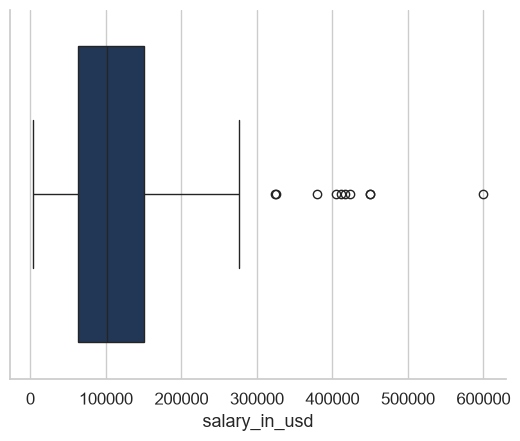

In [373]:
sns.boxplot(data=data,x="salary_in_usd");
plt.savefig('images/salary_chart1.png', dpi=300, bbox_inches='tight')
plt.show()

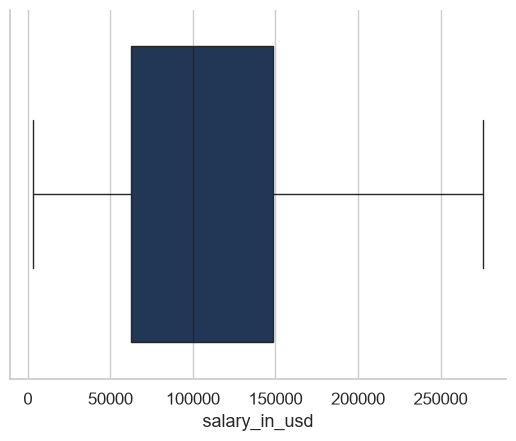

In [374]:
data = data[data.salary_in_usd < 300_000]
sns.boxplot(data=data,x="salary_in_usd");
plt.savefig('images/salary_chart2.png', dpi=300, bbox_inches='tight')
plt.show()

In [375]:
spearmanr(data.salary_in_usd, data.experience_level) # p-value < 0.05 

SignificanceResult(statistic=np.float64(0.5579476468827914), pvalue=np.float64(3.795022662679301e-50))

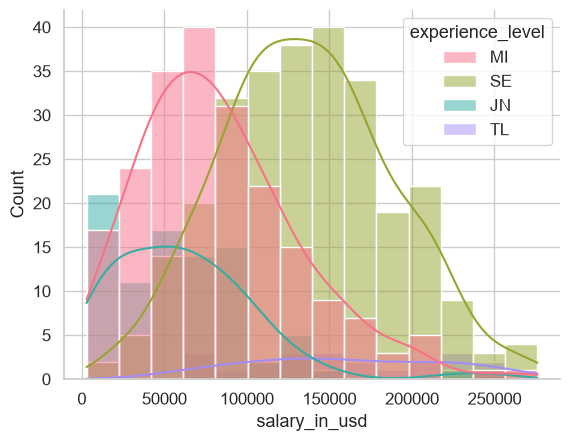

In [376]:
sns.histplot(data=data, x="salary_in_usd", hue="experience_level", kde=True);
plt.savefig('images/salary_chart3.png', dpi=300, bbox_inches='tight')
plt.show()

In [377]:
spearmanr(data.salary_in_usd, data.company_size)

SignificanceResult(statistic=np.float64(-0.10308939513387676), pvalue=np.float64(0.011726080444722028))

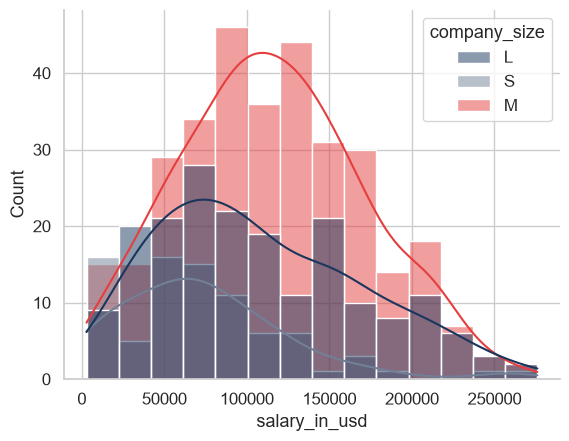

In [378]:
sns.histplot(data=data, x="salary_in_usd", hue="company_size", kde=True);
plt.savefig('images/salary_chart4.png', dpi=300, bbox_inches='tight')
plt.show()

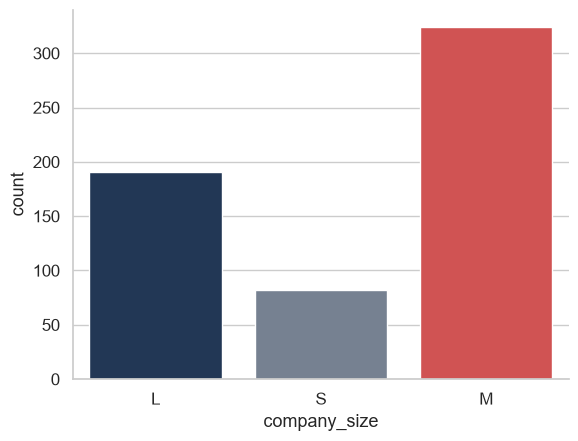

In [379]:
sns.countplot(data=data, x="company_size", hue="company_size", legend=False);
plt.savefig('images/salary_chart5.png', dpi=300, bbox_inches='tight')
plt.show()

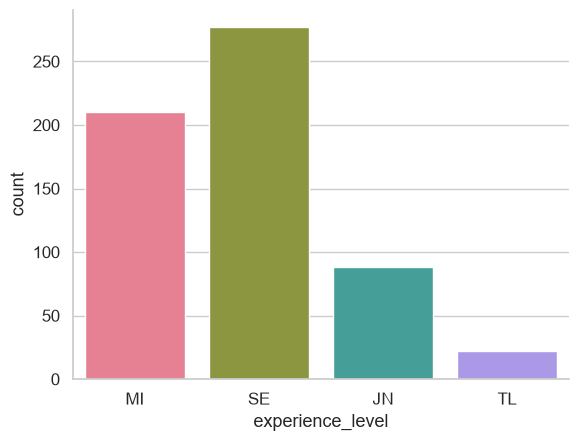

In [380]:
sns.countplot(data=data, x="experience_level", hue="experience_level", legend=False);
plt.savefig('images/salary_chart6.png', dpi=300, bbox_inches='tight')
plt.show()

2. **Распределение грейдов:** Как распределены позиции (грейды) сотрудников в компаниях разного размера? Какие выводы можно сделать на основе этого распределения?

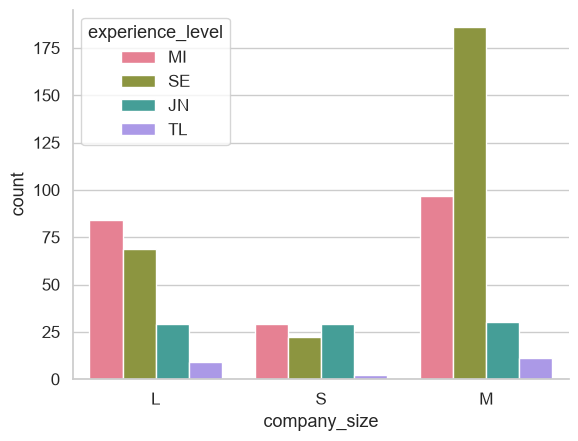

In [381]:
sns.countplot(data=data, x="company_size", hue="experience_level");
plt.savefig('images/salary_chart7.png', dpi=300, bbox_inches='tight')
plt.show()

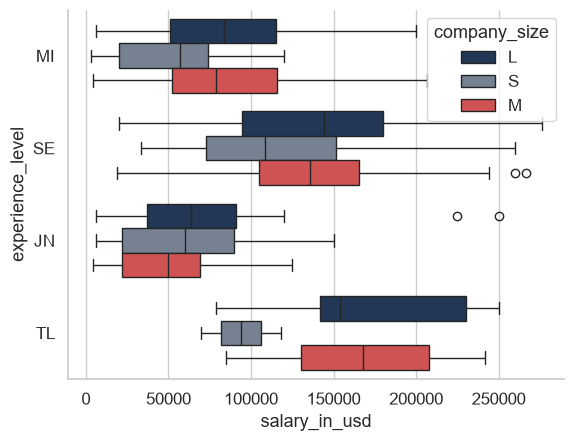

In [382]:
sns.boxplot(data=data, x="salary_in_usd", y="experience_level", hue='company_size');
plt.savefig('images/salary_chart8.png', dpi=300, bbox_inches='tight')
plt.show()

1. Компании размера M больше нанимают сотрудников грейда Senior.
2. Компании размера L больше нанимают сотрудников грейда Middle.
3. Компании размера L нанимают сотрудников грейда Middle и выделяют средства, чтобы развивать их до уровня Senior.
4. Компании размера M сразу нанимают сотрудников грейда Senior, чтобы бизнес получил пользу быстрее.
5. Компании размера S нанимают сотрудников всех грейдов равномерно.
6. Компании всех размеров редко нанимают сотрудников уровня TeamLead. Меньше всего тимлидов нанимают маленькие компании.


3. **Выбор компании:** В компанию какого размера выгоднее устраиваться кандидатам уровней *Middle* и *Senior*?

In [383]:
middle = data[data.experience_level == "MI"]
# Принудительно меняем тип столбца на дробный, чтобы новые версии разрешили запись
middle['salary_in_usd'] = middle['salary_in_usd'].astype('float64')


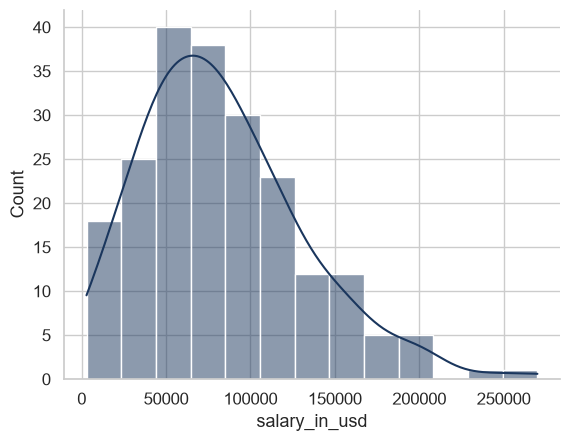

In [384]:
sns. histplot(data=middle, x="salary_in_usd", kde=True);
plt.savefig('images/salary_chart9.png', dpi=300, bbox_inches='tight')
plt.show()

In [385]:
tr_data, l = stats.boxcox(middle.salary_in_usd)

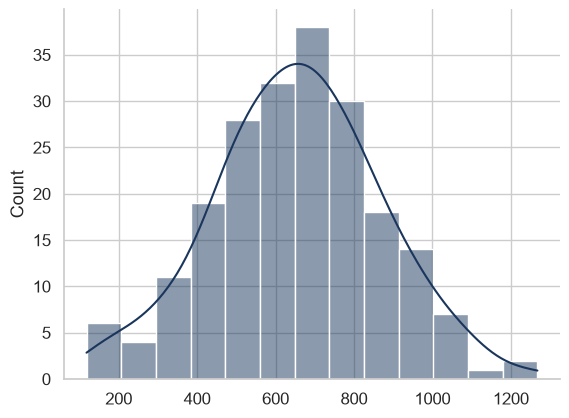

In [397]:
sns.histplot(tr_data, kde=True)
plt.savefig('images/salary_chart10.png', dpi=300, bbox_inches='tight')
plt.show()

In [387]:
middle.loc[:, ('salary_in_usd')] = tr_data

In [388]:
one_way = ols('salary_in_usd ~ company_size', middle).fit()
anova_lm(one_way) # отвергаем Но гипотезу, что у нас нет разницы в зарплате между размерами компаний

,df,sum_sq,mean_sq,F,PR(>F)
company_size,2.0,7.797339e+05,389866.933074,9.229123,0.000145
Residual,207.0,8.744325e+06,42243.116633,NaN,NaN


In [389]:
middle.shape # маленькая выборка

(210, 10)

In [390]:
middle_s = middle[middle.company_size == 'S'].salary_in_usd
middle_m = middle[middle.company_size == 'M'].salary_in_usd
middle_l = middle[middle.company_size == 'L'].salary_in_usd

In [391]:
stats.levene(middle_s, middle_m, middle_l) # p-value > 0.05, разница в дисперсиях между группами, не можем отклонить Но
# но у нас маленькая выборка

LeveneResult(statistic=np.float64(0.5807501532259973), pvalue=np.float64(0.5603874299118398))

In [401]:
print(pairwise_tukeyhsd(endog=middle.salary_in_usd, alpha=0.05, groups=middle['company_size'])) #если стоит выбор между организациями Мидлу лучше выбрать L или M

  Multiple Comparison of Means - Tukey HSD, FWER=0.05   
group1 group2  meandiff p-adj    lower    upper   reject
--------------------------------------------------------
     L      M  -10.7662 0.9342  -83.0818  61.5494  False
     L      S -181.7997 0.0002 -286.3003 -77.2991   True
     M      S -171.0335 0.0003 -273.7212 -68.3458   True
--------------------------------------------------------


In [393]:
senior = data[data.experience_level == "SE"]

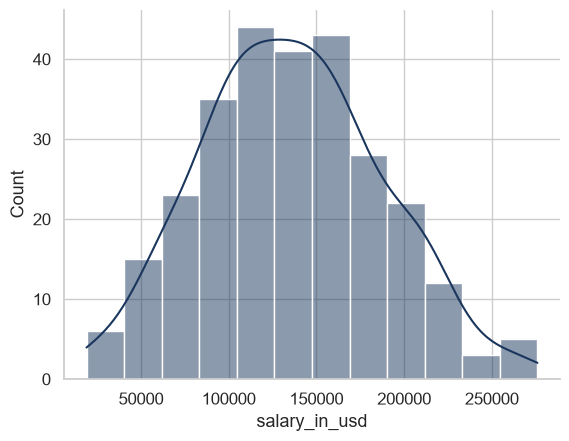

In [394]:
sns. histplot(data=senior, x="salary_in_usd", kde=True);
plt.savefig('images/salary_chart11.png', dpi=300, bbox_inches='tight')
plt.show()

In [395]:
one_way = ols('salary_in_usd ~ company_size', senior).fit()
anova_lm(one_way) # нет статистически значимых различий в зарплате между размерами компаний

,df,sum_sq,mean_sq,F,PR(>F)
company_size,2.0,9.408313e+09,4.704156e+09,1.807669,0.165987
Residual,274.0,7.130390e+11,2.602332e+09,NaN,NaN


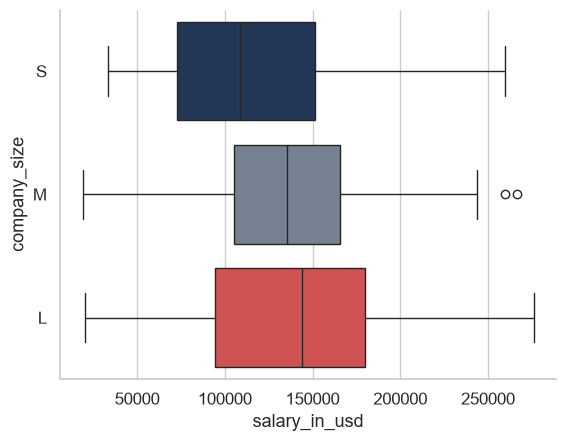

In [396]:
sns.boxplot(data=senior, x='salary_in_usd', y='company_size', hue='company_size'); #сеньерам не принципиально в какую организацию по размеру устраиваться
plt.savefig('images/salary_chart12.png', dpi=300, bbox_inches='tight')
plt.show()

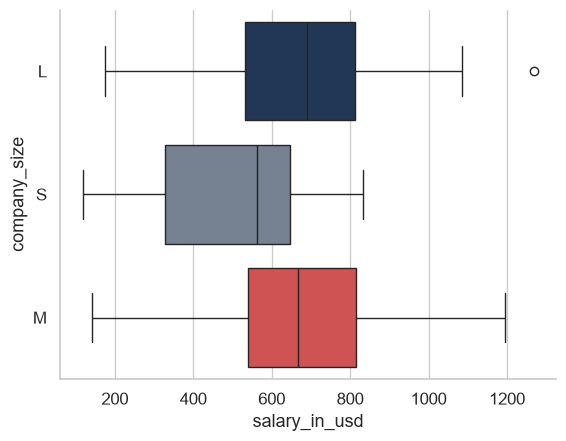

In [ ]:
sns.boxplot(data=middle, x='salary_in_usd', y='company_size', hue='company_size'); #мидлам лучше устраиваться в L или M размера компанию
plt.savefig('images/salary_chart13.png', dpi=300, bbox_inches='tight')
plt.show()

1. Специалисту грейда Middle выгоднее работать в компании размеров M и L.
2. Зарплата Senior-специалиста не зависит от размера компании.